# 2. ES Seasonal Calendar Strategy - Parameter Optimization

## Professional Sequential Optimization with Realistic Costs

This notebook performs a sequential optimization of the ES Seasonal
Calendar strategy using In-Sample data (2009-2019), on intraday bars
with prop-firm-compliant trading hours (flat by 4:30 PM ET, no new
entries opened during the 4:30 PM - 6:00 PM ET maintenance window).

Optimization Process (Sequential):
1. Best Days of Week
2. Best Months
3. Stop Loss Percentage
4. Take Profit Percentage
5. Short-Term Volatility Filter (proxy for the original "VIX < 30"
   constraint, added after diagnosing a concentrated risk-off episode
   in Nov 2025 during the previous hypothesis test)

Cost Assumptions (1 contract ES): Commission $2.00 per side = $4.00
round trip, Slippage 0.5 ticks = $6.25, Total cost per trade = $10.25

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## CONFIGURE PATHS AND IMPORT

In [2]:
project_root = Path().resolve().parent.parent
sys.path.append(str(project_root / 'utils'))

from utils import (
    load_data_from_mongo,
    compute_metrics,
    plot_equity_curve,
    plot_trade_distribution,
    plot_equity_curve_dollars,
    compute_yearly_pnl_dollars,
    walk_forward_calendar_analysis
)

sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10
print("Utils imported successfully.")

Utils imported successfully.


## LOAD DATA, TRADING HOURS AND COST CONFIGURATION

In [3]:
# Load intraday data
df_15min = load_data_from_mongo('es_15min')
print(f"Data loaded: {len(df_15min)} bars")
print(f"Date range: {df_15min.index.min()} -> {df_15min.index.max()}")

df_is_15min = df_15min[(df_15min.index >= '2009-09-27') & (df_15min.index < '2020-01-01')]
df_oos_15min = df_15min[df_15min.index >= '2020-01-01']
print(f"\nIn-Sample (IS): {len(df_is_15min)} bars ({df_is_15min.index.min()} -> {df_is_15min.index.max()})")
print(f"Out-of-Sample (OOS): {len(df_oos_15min)} bars ({df_oos_15min.index.min()} -> {df_oos_15min.index.max()})")

# --- Costs ---
CONTRACT_MULTIPLIER = 50      # $ per point, ES
CONTRACTS = 1
COMMISSION_PER_CONTRACT = 2.0
SLIPPAGE_TICKS = 0.5
SLIPPAGE_COST = SLIPPAGE_TICKS * 12.50
COST_PER_TRADE = COMMISSION_PER_CONTRACT * 2 + SLIPPAGE_COST

# --- Trading hours (prop-firm compliant, validated in 01_Hypothesis_Definition) ---
MARKET_CLOSE_HOUR, MARKET_CLOSE_MIN = 16, 30    # 4:30 PM ET - flat by here
MARKET_REOPEN_HOUR, MARKET_REOPEN_MIN = 18, 0   # 6:00 PM ET - trading resumes
ENTRY_CUTOFF_HOUR, ENTRY_CUTOFF_MIN = 15, 30    # last new entry: 3:30 PM ET

assert (MARKET_CLOSE_HOUR, MARKET_CLOSE_MIN) == (16, 30), "Market close must be 4:30 PM ET"
assert (MARKET_REOPEN_HOUR, MARKET_REOPEN_MIN) == (18, 0), "Reopen must be 6:00 PM ET"

print("\n" + "="*70)
print("COST ASSUMPTIONS (1 contract ES)")
print("="*70)
print(f"Total cost per trade: ${COST_PER_TRADE:.2f}")

Data loaded: 397663 bars
Date range: 2009-09-27 18:00:00 -> 2026-08-21 16:45:00

In-Sample (IS): 241077 bars (2009-09-27 18:00:00 -> 2019-12-31 16:45:00)
Out-of-Sample (OOS): 156586 bars (2020-01-01 18:00:00 -> 2026-08-21 16:45:00)

COST ASSUMPTIONS (1 contract ES)
Total cost per trade: $10.25


## HELPER FUNCTIONS

Intraday calendar backtest with trend filter, prop-firm-compliant
hours, and an optional short-term volatility filter. The volatility
filter compares realized volatility over a short window (default 5
days) against a longer baseline (default 20 days); if the ratio
exceeds `vol_filter_ratio`, no new entries are taken that day. It
uses the PRIOR day's completed ratio to avoid lookahead bias, since
intraday entries happen before the current day's close.

In [4]:
def compute_daily_vol_ratio(df_intraday, vol_lookback_short=5, vol_lookback_long=20):
    """
    Compute a daily short-term/long-term realized volatility ratio from
    intraday data, shifted by one day to avoid lookahead bias. Returns
    a Series indexed by date (not datetime).
    """
    daily_close = df_intraday.resample('D')['close'].last().dropna()
    daily_ret = daily_close.pct_change()
    vol_short = daily_ret.rolling(vol_lookback_short).std()
    vol_long = daily_ret.rolling(vol_lookback_long).std()
    vol_ratio = (vol_short / vol_long).shift(1)  # use prior day's completed ratio
    vol_ratio.index = vol_ratio.index.date
    return vol_ratio


def run_calendar_backtest_intraday(df, entry_days, entry_months,
                                     target_pct=1.5, stop_pct=1.0,
                                     entry_cutoff_hour=15, entry_cutoff_min=30,
                                     market_close_hour=16, market_close_min=30,
                                     market_reopen_hour=18, market_reopen_min=0,
                                     vol_filter_ratio=None,
                                     vol_lookback_short=5, vol_lookback_long=20):
    """
    Intraday calendar-based backtest with trend filter, prop-firm-compliant
    trading hours, and an optional short-term volatility filter.

    vol_filter_ratio : float or None
        If set, blocks new entries on days where the short/long realized
        volatility ratio (as of the prior day's close) exceeds this value —
        a proxy for the original "VIX < 30" constraint, using ES's own
        realized volatility since no VIX series is loaded.
    """
    df = df.copy()
    df['sma50'] = df['close'].rolling(50).mean()
    df['sma200'] = df['close'].rolling(200).mean()
    df['sma50_above_sma200'] = df['sma50'] > df['sma200']

    df['dayofweek'] = df.index.dayofweek
    df['month'] = df.index.month
    df['hour'] = df.index.hour
    df['minute'] = df.index.minute
    df['date'] = df.index.date

    entry_time_ok = (df['hour'] < entry_cutoff_hour) | (
        (df['hour'] == entry_cutoff_hour) & (df['minute'] <= entry_cutoff_min)
    )

    in_maintenance_window = (
        (df['hour'] > market_close_hour) |
        ((df['hour'] == market_close_hour) & (df['minute'] >= market_close_min))
    ) & (df['hour'] < market_reopen_hour)

    entry_condition = (
        df['dayofweek'].isin(entry_days) &
        df['month'].isin(entry_months) &
        df['sma50_above_sma200'] &
        entry_time_ok &
        ~in_maintenance_window
    )

    if vol_filter_ratio is not None:
        vol_ratio = compute_daily_vol_ratio(df, vol_lookback_short, vol_lookback_long)
        df['vol_ratio'] = df['date'].map(vol_ratio)
        vol_ok = df['vol_ratio'].notna() & (df['vol_ratio'] <= vol_filter_ratio)
        entry_condition = entry_condition & vol_ok

    df['entry_signal'] = entry_condition

    trades = []
    position = None
    entry_price = None
    entry_time = None
    current_date = None

    for idx, row in df.iterrows():
        if current_date is not None and row['date'] != current_date and position is not None:
            trades.append({
                'entry_time': entry_time, 'exit_time': idx,
                'entry_price': entry_price, 'exit_price': row['open'],
                'type': position, 'reason': 'forced_eod_gap'
            })
            position = None
        current_date = row['date']

        if position is not None:
            past_close = (row['hour'] > market_close_hour) or (
                row['hour'] == market_close_hour and row['minute'] >= market_close_min
            )
            hit_target = row['high'] >= entry_price * (1 + target_pct / 100)
            hit_stop = row['low'] <= entry_price * (1 - stop_pct / 100)

            if hit_stop:
                exit_price = entry_price * (1 - stop_pct / 100)
                reason = 'stop_loss'
            elif hit_target:
                exit_price = entry_price * (1 + target_pct / 100)
                reason = 'take_profit'
            elif past_close:
                exit_price = row['close']
                reason = 'time_stop'
            else:
                continue

            trades.append({
                'entry_time': entry_time, 'exit_time': idx,
                'entry_price': entry_price, 'exit_price': exit_price,
                'type': position, 'reason': reason
            })
            position = None
            continue

        if row['entry_signal'] and position is None:
            position = 'long'
            entry_price = row['close']
            entry_time = idx

    trades_df = pd.DataFrame(trades)
    if len(trades_df) > 0:
        trades_df['pnl'] = (trades_df['exit_price'] - trades_df['entry_price']) / trades_df['entry_price'] * 100
        trades_df['win'] = trades_df['pnl'] > 0
    return trades_df


def get_metrics(df, entry_days, entry_months, stop_pct, target_pct,
                 vol_filter_ratio=None, cost_per_trade=0.0,
                 contract_multiplier=CONTRACT_MULTIPLIER, contracts=CONTRACTS):
    """Get metrics for a parameter combination (intraday, prop-firm compliant)."""
    trades = run_calendar_backtest_intraday(
        df, entry_days, entry_months,
        target_pct=target_pct, stop_pct=stop_pct,
        entry_cutoff_hour=ENTRY_CUTOFF_HOUR, entry_cutoff_min=ENTRY_CUTOFF_MIN,
        market_close_hour=MARKET_CLOSE_HOUR, market_close_min=MARKET_CLOSE_MIN,
        market_reopen_hour=MARKET_REOPEN_HOUR, market_reopen_min=MARKET_REOPEN_MIN,
        vol_filter_ratio=vol_filter_ratio
    )
    if len(trades) == 0:
        return {'profit_factor': 0, 'num_trades': 0, 'win_rate': 0,
                'expectancy': 0, 'total_pnl': 0, 'sharpe': 0, 'max_drawdown': 0}
    return compute_metrics(trades, contract_multiplier=contract_multiplier,
                            cost_per_trade=cost_per_trade, contracts=contracts)

## SEQUENTIAL OPTIMIZATION (IN-SAMPLE ONLY)

All five steps below run exclusively on 2009-2019 data. The
out-of-sample set (2020-2026) is touched only once, in the
validation cell after this section.

In [5]:
print("\n" + "="*70)
print("SEQUENTIAL OPTIMIZATION (IN-SAMPLE)")
print("="*70)

best_params = {}

# Step 1: Optimize Days of Week
print("\nStep 1: Optimizing Days of Week")
day_combinations = [
    [1, 2, 3, 4],  # Tue-Fri
    [1, 2, 3],     # Tue-Thu
    [2, 3, 4],     # Wed-Fri
    [1, 2, 4],     # Tue, Wed, Fri
    [1, 3, 4],     # Tue, Thu, Fri
    [2, 3],        # Wed-Thu
    [1, 2],        # Tue-Wed
    [3, 4],        # Thu-Fri
]
day_results = []
for days in day_combinations:
    metrics = get_metrics(df_is_15min, days, [4, 7, 10, 11], 1.0, 1.5, cost_per_trade=COST_PER_TRADE)
    day_results.append({'days': days, 'num_trades': metrics['num_trades'],
                         'pf': metrics['profit_factor'], 'win_rate': metrics['win_rate'],
                         'expectancy': metrics['expectancy']})
day_df = pd.DataFrame(day_results)
print(day_df.to_string(index=False))
best_days = day_df.loc[day_df['pf'].idxmax(), 'days']
best_params['days'] = best_days
print(f"\nBest days: {best_days}")

# Step 2: Optimize Months
print("\nStep 2: Optimizing Months")
month_combinations = [
    [4, 7, 10, 11],  # Apr, Jul, Oct, Nov
    [7, 10, 11],     # Jul, Oct, Nov
    [4, 10, 11],     # Apr, Oct, Nov
    [4, 7, 11],      # Apr, Jul, Nov
    [7, 11],         # Jul, Nov
    [10, 11],        # Oct, Nov
    [4, 7, 10],      # Apr, Jul, Oct
]
month_results = []
for months in month_combinations:
    metrics = get_metrics(df_is_15min, best_days, months, 1.0, 1.5, cost_per_trade=COST_PER_TRADE)
    month_results.append({'months': months, 'num_trades': metrics['num_trades'],
                           'pf': metrics['profit_factor'], 'win_rate': metrics['win_rate'],
                           'expectancy': metrics['expectancy']})
month_df = pd.DataFrame(month_results)
print(month_df.to_string(index=False))
best_months = month_df.loc[month_df['pf'].idxmax(), 'months']
best_params['months'] = best_months
print(f"\nBest months: {best_months}")

# Step 3: Optimize Stop Loss
print("\nStep 3: Optimizing Stop Loss")
stop_values = [0.5, 0.7, 1.0, 1.2, 1.5]
stop_results = []
for stop in stop_values:
    metrics = get_metrics(df_is_15min, best_days, best_months, stop, 1.5, cost_per_trade=COST_PER_TRADE)
    stop_results.append({'stop_pct': stop, 'num_trades': metrics['num_trades'],
                          'pf': metrics['profit_factor'], 'win_rate': metrics['win_rate'],
                          'expectancy': metrics['expectancy']})
stop_df = pd.DataFrame(stop_results)
print(stop_df.to_string(index=False))
best_stop = stop_df.loc[stop_df['pf'].idxmax(), 'stop_pct']
best_params['stop_pct'] = best_stop
print(f"\nBest stop: {best_stop}%")

# Step 4: Optimize Take Profit
print("\nStep 4: Optimizing Take Profit")
target_values = [1.0, 1.2, 1.5, 1.8, 2.0, 2.5]
target_results = []
for target in target_values:
    metrics = get_metrics(df_is_15min, best_days, best_months, best_stop, target, cost_per_trade=COST_PER_TRADE)
    target_results.append({'target_pct': target, 'num_trades': metrics['num_trades'],
                            'pf': metrics['profit_factor'], 'win_rate': metrics['win_rate'],
                            'expectancy': metrics['expectancy']})
target_df = pd.DataFrame(target_results)
print(target_df.to_string(index=False))
best_target = target_df.loc[target_df['pf'].idxmax(), 'target_pct']
best_params['target_pct'] = best_target
print(f"\nBest target: {best_target}%")

# Step 5: Optimize Short-Term Volatility Filter
print("\nStep 5: Optimizing Short-Term Volatility Filter")
print("(Proxy for the original 'VIX < 30' constraint, using ES's own")
print(" 5-day/20-day realized volatility ratio, since no VIX series is loaded)")
vol_filter_values = [None, 2.0, 1.8, 1.5, 1.3]
vol_results = []
for vf in vol_filter_values:
    metrics = get_metrics(df_is_15min, best_days, best_months, best_stop, best_target,
                           vol_filter_ratio=vf, cost_per_trade=COST_PER_TRADE)
    vol_results.append({'vol_filter_ratio': vf, 'num_trades': metrics['num_trades'],
                         'pf': metrics['profit_factor'], 'win_rate': metrics['win_rate'],
                         'expectancy': metrics['expectancy'],
                         'max_drawdown': metrics['max_drawdown']})
vol_df = pd.DataFrame(vol_results)
print(vol_df.to_string(index=False))

# --- FIX: pd.DataFrame coerces the mixed None/float column to NaN, losing
# the distinction between "no filter" (None) and an actual numeric ratio.
# idxmax() on a NaN-containing row returns nan, not None, which would then
# make `vol_filter_ratio is not None` evaluate True downstream and block
# every entry. Convert back to None explicitly before storing.
best_vol_filter = vol_df.loc[vol_df['pf'].idxmax(), 'vol_filter_ratio']
if pd.isna(best_vol_filter):
    best_vol_filter = None
best_params['vol_filter_ratio'] = best_vol_filter
print(f"\nBest volatility filter ratio: {best_vol_filter}")

print("\n" + "="*70)
print("OPTIMAL PARAMETERS")
print("="*70)
for k, v in best_params.items():
    print(f"  {k}: {v}")


SEQUENTIAL OPTIMIZATION (IN-SAMPLE)

Step 1: Optimizing Days of Week
        days  num_trades       pf  win_rate  expectancy
[1, 2, 3, 4]         616 1.400711 57.467532    0.086256
   [1, 2, 3]         462 1.458537 57.792208    0.093973
   [2, 3, 4]         464 1.439136 57.327586    0.093903
   [1, 2, 4]         459 1.350632 57.298475    0.078249
   [1, 3, 4]         463 1.359731 57.451404    0.078831
      [2, 3]         310 1.552215 57.741935    0.109202
      [1, 2]         305 1.406063 57.704918    0.085895
      [3, 4]         311 1.395638 57.234727    0.086610

Best days: [2, 3]

Step 2: Optimizing Months
        months  num_trades       pf  win_rate  expectancy
[4, 7, 10, 11]         310 1.552215 57.741935    0.109202
   [7, 10, 11]         237 1.615801 59.071730    0.120476
   [4, 10, 11]         235 1.525700 58.297872    0.109330
    [4, 7, 11]         228 1.507557 58.333333    0.096063
       [7, 11]         155 1.588406 60.645161    0.107114
      [10, 11]         162 1.600

## VALIDATE IN OUT-OF-SAMPLE (2020-2026)

First and only time the optimized parameters touch OOS data.


OOS VALIDATION (2020-2026)
Number of trades: 137
Win rate: 51.09%
Average win: 0.62%
Average loss: -0.64%
Profit Factor: 1.00
Expectancy per trade: 0.0012%
Total P&L: 0.16%
Sharpe Ratio: 0.02
Maximum Drawdown: -12.30%


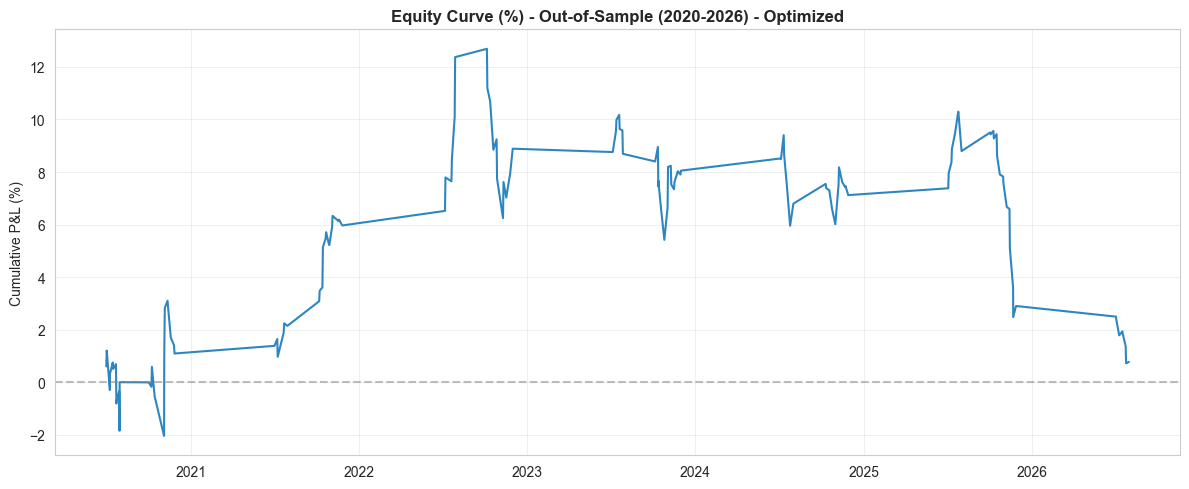

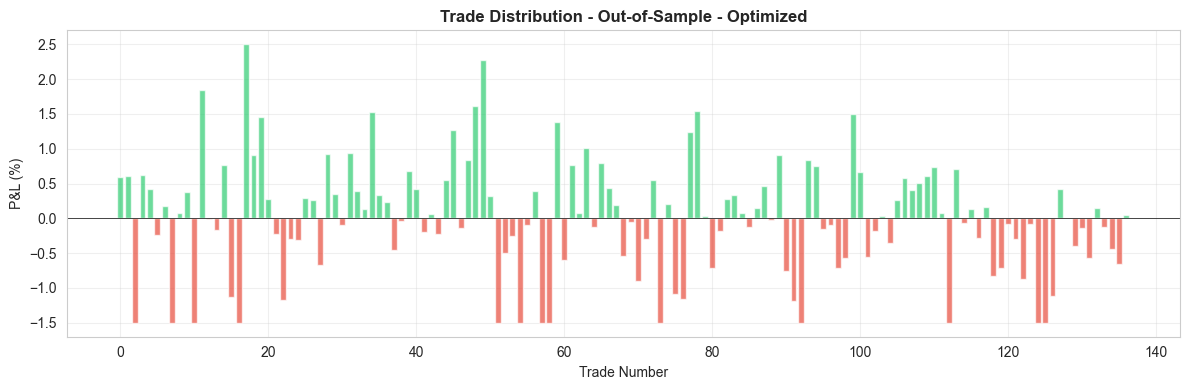


Exit Reason Breakdown (OOS):
reason
time_stop      123
stop_loss       13
take_profit      1
Name: count, dtype: int64

Win rate by reason (OOS):
reason
stop_loss      0.000000
take_profit    1.000000
time_stop      0.560976
Name: win, dtype: float64


In [6]:
print("\n" + "="*70)
print("OOS VALIDATION (2020-2026)")
print("="*70)

trades_oos = run_calendar_backtest_intraday(
    df_oos_15min,
    entry_days=best_params['days'],
    entry_months=best_params['months'],
    target_pct=best_params['target_pct'],
    stop_pct=best_params['stop_pct'],
    entry_cutoff_hour=ENTRY_CUTOFF_HOUR, entry_cutoff_min=ENTRY_CUTOFF_MIN,
    market_close_hour=MARKET_CLOSE_HOUR, market_close_min=MARKET_CLOSE_MIN,
    market_reopen_hour=MARKET_REOPEN_HOUR, market_reopen_min=MARKET_REOPEN_MIN,
    vol_filter_ratio=best_params['vol_filter_ratio']
)

if len(trades_oos) > 0:
    metrics_oos = compute_metrics(
        trades_oos, contract_multiplier=CONTRACT_MULTIPLIER,
        cost_per_trade=COST_PER_TRADE, contracts=CONTRACTS
    )
    print(f"Number of trades: {metrics_oos['num_trades']}")
    print(f"Win rate: {metrics_oos['win_rate']:.2f}%")
    print(f"Average win: {metrics_oos['avg_win']:.2f}%")
    print(f"Average loss: {metrics_oos['avg_loss']:.2f}%")
    print(f"Profit Factor: {metrics_oos['profit_factor']:.2f}")
    print(f"Expectancy per trade: {metrics_oos['expectancy']:.4f}%")
    print(f"Total P&L: {metrics_oos['total_pnl']:.2f}%")
    print(f"Sharpe Ratio: {metrics_oos['sharpe']:.2f}")
    print(f"Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")

    plot_equity_curve(trades_oos, title='Equity Curve (%) - Out-of-Sample (2020-2026) - Optimized')
    plot_trade_distribution(trades_oos, title='Trade Distribution - Out-of-Sample - Optimized')

    print("\nExit Reason Breakdown (OOS):")
    print(trades_oos['reason'].value_counts())

    print("\nWin rate by reason (OOS):")
    print(trades_oos.groupby('reason')['win'].mean())
else:
    print("No trades in OOS.")

## YEARLY P&L IN DOLLARS AND EQUITY CURVE (OUT-OF-SAMPLE)

Checks specifically whether the volatility filter reduced the
concentrated losses seen in Oct-Nov 2025 without eroding the good
years, rather than relying on aggregate PF/Sharpe alone.

YEARLY P&L IN DOLLARS (1 CONTRACT(S), MULTIPLIER=$50)
Costs included: $10.25 per trade (commission + slippage)
      pnl_dollars  num_trades  avg_pnl_per_trade
year                                            
2020      1215.19          25              48.61
2021     10467.75          19             550.93
2022      6066.19          20             303.31
2023     -2264.75          23             -98.47
2024     -2923.38          18            -162.41
2025    -15092.25          24            -628.84
2026     -8107.00           8           -1013.38

TOTAL SUMMARY
Total P&L: $-10,638.25
Total trades: 137
Average P&L per trade: $-77.65
Average trades per year: 19.6

Positive years: 3
Negative years: 4


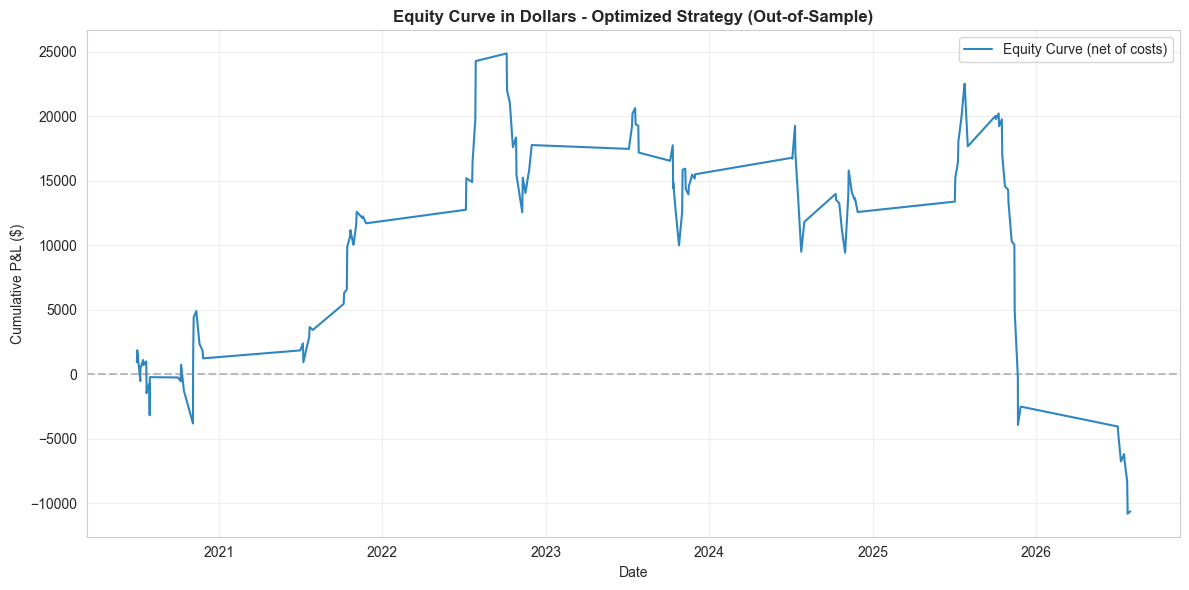


Final net P&L: $-10,638.25
Total costs paid: $1,404.25
Gross P&L (before costs): $-9,234.00


In [7]:
if len(trades_oos) > 0:
    yearly_pnl_oos_optimized = compute_yearly_pnl_dollars(
        trades_oos, contract_multiplier=CONTRACT_MULTIPLIER,
        contracts=CONTRACTS, cost_per_trade=COST_PER_TRADE
    )

    equity_oos_optimized_dollars = plot_equity_curve_dollars(
        trades_oos, contract_multiplier=CONTRACT_MULTIPLIER,
        contracts=CONTRACTS, cost_per_trade=COST_PER_TRADE,
        title='Equity Curve in Dollars - Optimized Strategy (Out-of-Sample)'
    )

## WALK-FORWARD ANALYSIS

In [8]:
wf_results = walk_forward_calendar_analysis(
    df_15min, train_years=5, test_years=1,
    start_year=2009, end_year=2026,
    cost_per_trade=COST_PER_TRADE, contract_multiplier=CONTRACT_MULTIPLIER, contracts=CONTRACTS,
    entry_cutoff_hour=ENTRY_CUTOFF_HOUR, entry_cutoff_min=ENTRY_CUTOFF_MIN,
    market_close_hour=MARKET_CLOSE_HOUR, market_close_min=MARKET_CLOSE_MIN,
    market_reopen_hour=MARKET_REOPEN_HOUR, market_reopen_min=MARKET_REOPEN_MIN
)

print("\n" + "="*70)
print("WALK-FORWARD RESULTS SUMMARY")
print("="*70)
print(wf_results[['train_start', 'train_end', 'test_start', 'test_end',
                   'days', 'months', 'stop_pct', 'target_pct',
                   'test_num_trades', 'test_pf', 'test_sharpe', 'test_max_dd']].to_string(index=False))


Window: train 2009-2013, test 2014-2014
  Best days: [2, 3] (PF=1.58, n=136)
  Best months: [4, 7, 10] (PF=1.96)
  Best stop: 1.5% (PF=2.12)
  Best target: 1.5% (PF=2.12)

Window: train 2010-2014, test 2015-2015
  Best days: [1, 3, 4] (PF=1.72, n=225)
  Best months: [10, 11] (PF=2.09)
  Best stop: 1.5% (PF=2.62)
  Best target: 2.5% (PF=2.72)

Window: train 2011-2015, test 2016-2016
  Best days: [3, 4] (PF=1.70, n=159)
  Best months: [10, 11] (PF=2.24)
  Best stop: 1.5% (PF=2.60)
  Best target: 2.5% (PF=2.73)

Window: train 2012-2016, test 2017-2017
  Best days: [3, 4] (PF=1.36, n=146)
  Best months: [10, 11] (PF=1.90)
  Best stop: 1.0% (PF=1.90)
  Best target: 2.5% (PF=1.91)

Window: train 2013-2017, test 2018-2018
  Best days: [1, 2] (PF=1.55, n=143)
  Best months: [4, 7, 11] (PF=1.78)
  Best stop: 1.0% (PF=1.78)
  Best target: 1.2% (PF=1.80)

Window: train 2014-2018, test 2019-2019
  Best days: [1, 2] (PF=1.78, n=143)
  Best months: [7, 11] (PF=2.16)
  Best stop: 1.0% (PF=2.16)
  Be

## WALK-FORWARD CONSISTENCY CHECK

In [9]:
print("Test windows with PF > 1.0 (any edge at all):",
      (wf_results['test_pf'] > 1.0).sum(), "/", len(wf_results))
print("Test windows with PF > 1.3 (meets original threshold):",
      (wf_results['test_pf'] > 1.3).sum(), "/", len(wf_results))

print(f"\nAverage test PF across windows: {wf_results['test_pf'].mean():.2f}")
print(f"Median test PF across windows: {wf_results['test_pf'].median():.2f}")
print(f"Std dev of test PF across windows: {wf_results['test_pf'].std():.2f}")

print(f"\nAverage test Sharpe across windows: {wf_results['test_sharpe'].mean():.2f}")
print(f"Total test P&L across all windows: {wf_results['test_total_pnl'].sum():.2f}%")

print("\nParameter stability (how often each stop/target was chosen):")
print("Stop values chosen:", wf_results['stop_pct'].value_counts().to_dict())
print("Target values chosen:", wf_results['target_pct'].value_counts().to_dict())

Test windows with PF > 1.0 (any edge at all): 9 / 13
Test windows with PF > 1.3 (meets original threshold): 9 / 13

Average test PF across windows: 1.68
Median test PF across windows: 1.51
Std dev of test PF across windows: 0.97

Average test Sharpe across windows: 1.90
Total test P&L across all windows: 15.73%

Parameter stability (how often each stop/target was chosen):
Stop values chosen: {1.5: 7, 1.0: 3, 1.2: 3}
Target values chosen: {2.5: 8, 1.5: 3, 1.2: 1, 1.8: 1}


## FINAL DECISION

In [11]:
print("\n" + "="*70)
print("FINAL DECISION (WALK-FORWARD)")
print("="*70)

pct_windows_pf_pass = (wf_results['test_pf'] > 1.3).mean() * 100
avg_sharpe = wf_results['test_sharpe'].mean()
worst_window_dd = wf_results['test_max_dd'].min()
total_windows = len(wf_results)

print(f"Windows with PF > 1.3: {(wf_results['test_pf'] > 1.3).sum()}/{total_windows} ({pct_windows_pf_pass:.0f}%)")
print(f"Average test PF: {wf_results['test_pf'].mean():.2f} (median: {wf_results['test_pf'].median():.2f})")
print(f"Average test Sharpe: {avg_sharpe:.2f}")
print(f"Worst single-window drawdown: {worst_window_dd:.2f}%")
print(f"Total cumulative P&L across all windows: {wf_results['test_total_pnl'].sum():.2f}%")

print("\nWorst 3 windows (by PF):")
print(wf_results.nsmallest(3, 'test_pf')[['test_start', 'test_end', 'test_num_trades', 'test_pf', 'test_sharpe']].to_string(index=False))

if pct_windows_pf_pass >= 60 and avg_sharpe > 0.7:
    print("\nEncouraging: majority of independent windows show a real edge,")
    print("with consistent month selection (Oct-Nov core) and stable stop/target.")
    print("Day-of-week selection is less stable across windows — worth treating")
    print("as a secondary parameter rather than a fixed hard rule.")
else:
    print("\nEdge is not consistent enough across windows to proceed with confidence.")


FINAL DECISION (WALK-FORWARD)
Windows with PF > 1.3: 9/13 (69%)
Average test PF: 1.68 (median: 1.51)
Average test Sharpe: 1.90
Worst single-window drawdown: -9.28%
Total cumulative P&L across all windows: 15.73%

Worst 3 windows (by PF):
 test_start  test_end  test_num_trades  test_pf  test_sharpe
       2026      2026               10 0.256443    -8.185033
       2022      2022               25 0.489329    -4.816303
       2016      2016               11 0.835596    -1.200583

Encouraging: majority of independent windows show a real edge,
with consistent month selection (Oct-Nov core) and stable stop/target.
Day-of-week selection is less stable across windows — worth treating
as a secondary parameter rather than a fixed hard rule.
